In [11]:
import os
import glob
import pandas as pd

def load_and_merge_raman_data(folder_path):
    # 1. 폴더 내의 모든 .txt 파일 경로를 리스트로 가져오기
    file_pattern = os.path.join(folder_path, '*.txt')
    file_list = glob.glob(file_pattern)
    
    if not file_list:
        print("텍스트 파일을 찾을 수 없습니다. 경로를 확인해주세요.")
        return None

    data_list = []
    
    for file in file_list:
        filename = os.path.basename(file)
        
        # 2. 파일명 파싱을 통한 타겟 레이블(Target Label) 자동 생성 로직
        # 'sta-' 로 시작하면 Standard(표준), 'wea-' 로 시작하면 Weathered(풍화된)
        if filename.startswith('sta'):
            label = 'Standard'
        elif filename.startswith('wea'):
            label = 'Weathered'
        else:
            label = 'Unknown'
            
        # 3. 개별 txt 파일 로드 (라만 txt 파일은 보통 공백이나 탭으로 구분됨)
        # header=None 을 통해 첫 데이터가 열 이름으로 유실되는 것을 방지
        temp_df = pd.read_csv(file, sep='\s+', header=None, names=['Wavenumber', 'Intensity'])
        
        # 4. 머신러닝을 위한 행렬 전환 (Transpose)
        # 파수(Wavenumber)를 컬럼명으로 만들기 위해 인덱스로 설정 후 전치(T) 수행
        temp_df.set_index('Wavenumber', inplace=True)
        row_df = temp_df.T  # 1행짜리 데이터프레임으로 변환됨
        
        # 5. 메타데이터 (파일명과 타겟 레이블) 삽입
        row_df['Filename'] = filename
        row_df['Target'] = label
        
        data_list.append(row_df)
        
    # 6. 리스트에 담긴 모든 1행짜리 데이터프레임을 하나로 병합 (Merge)
    final_df = pd.concat(data_list, ignore_index=True)
    
    # 7. 식별을 위해 'Filename'과 'Target' 컬럼을 데이터프레임의 맨 앞으로 이동
    cols = ['Filename', 'Target'] + [c for c in final_df.columns if c not in ['Filename', 'Target']]
    final_df = final_df[cols]
    
    return final_df

# === 코드 실행부 ===
# 경로를 멘토님의 실제 환경에 맞게 지정하세요 (예: 'data/raw/')
RAW_DATA_PATH = '../data/raw/' 

df_raman = load_and_merge_raman_data(RAW_DATA_PATH)

if df_raman is not None:
    print(f"✅ 총 {df_raman.shape[0]}개의 샘플과 {df_raman.shape[1]-2}개의 파수(Feature) 대역이 성공적으로 병합되었습니다.\n")
    print("=== 데이터프레임 미리보기 (상위 5행) ===")
    display(df_raman.head())

✅ 총 173개의 샘플과 5086개의 파수(Feature) 대역이 성공적으로 병합되었습니다.

=== 데이터프레임 미리보기 (상위 5행) ===


Wavenumber,Filename,Target,201.866871,204.75425,207.640597,210.525912,213.410197,216.293452,219.175678,222.056878,...,3482.555849,3484.458372,3486.3604,3488.261932,3490.16297,3492.063513,3493.963561,3495.863115,3497.762175,3499.66074
0,wea-56.txt,Weathered,933.0,929.75,927.5,930.75,942.0,928.5,947.5,937.75,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,wea-42.txt,Weathered,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,wea-95.txt,Weathered,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,wea-81.txt,Weathered,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,sta-3.txt,Standard,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
%pip install pandas

Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 10.8 MB 4.7 MB/s eta 0:00:01
     |████████████████████████████████| 5.3 MB 6.8 MB/s eta 0:00:01
     |████████████████████████████████| 348 kB 10.6 MB/s eta 0:00:01
     |████████████████████████████████| 508 kB 6.7 MB/s eta 0:00:01
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


Matplotlib is building the font cache; this may take a moment.


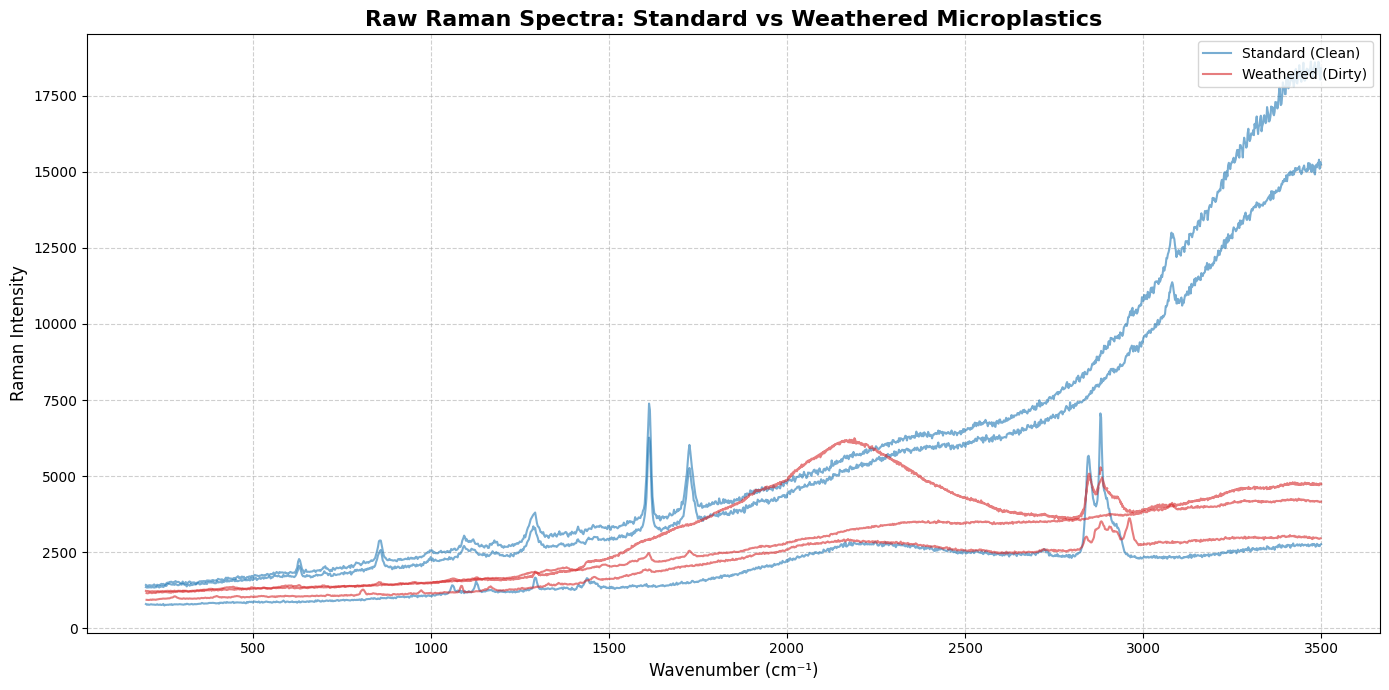

In [14]:
import matplotlib.pyplot as plt
import numpy as np

# 그래프 크기 설정
plt.figure(figsize=(14, 7))

# 1. Standard(표준) 샘플 3개와 Weathered(풍화된) 샘플 3개를 무작위로 뽑기
sample_standard = df_raman[df_raman['Target'] == 'Standard'].head(3)
sample_weathered = df_raman[df_raman['Target'] == 'Weathered'].head(3)

# 2. 파수(Wavenumber) 데이터 추출 (3번째 열부터 끝까지)
wavenumbers = df_raman.columns[2:].astype(float)

# 3. Standard(표준) 플라스틱 스펙트럼 그리기 (파란색)
for index, row in sample_standard.iterrows():
    # 데이터 강도(Intensity) 추출
    intensities = row[2:].values
    plt.plot(wavenumbers, intensities, color='#1f77b4', alpha=0.6, linewidth=1.5, 
             label='Standard (Clean)' if index == sample_standard.index[0] else "")

# 4. Weathered(풍화된) 플라스틱 스펙트럼 그리기 (빨간색)
for index, row in sample_weathered.iterrows():
    # 데이터 강도(Intensity) 추출
    intensities = row[2:].values
    plt.plot(wavenumbers, intensities, color='#d62728', alpha=0.6, linewidth=1.5, 
             label='Weathered (Dirty)' if index == sample_weathered.index[0] else "")

# 그래프 디자인 요소 추가
plt.title("Raw Raman Spectra: Standard vs Weathered Microplastics", fontsize=16, fontweight='bold')
plt.xlabel("Wavenumber (cm⁻¹)", fontsize=12)
plt.ylabel("Raman Intensity", fontsize=12)
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

# 그래프 화면에 출력!
plt.show()

In [13]:
%pip install matplotlib

Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 7.8 MB 7.0 MB/s eta 0:00:01
     |████████████████████████████████| 4.7 MB 5.3 MB/s eta 0:00:01
     |████████████████████████████████| 249 kB 7.1 MB/s eta 0:00:01
     |████████████████████████████████| 2.9 MB 8.0 MB/s eta 0:00:01
     |████████████████████████████████| 64 kB 4.9 MB/s eta 0:00:011
     |████████████████████████████████| 122 kB 7.9 MB/s eta 0:00:01
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.
